# EDA: одностороннее и двустороннее поражение глаз

## 1. Вопрос и гипотеза

Как часто класс заболевания отмечен только на одном из двух глаз пациента?
Гипотеза №3 из `intro.ipynb`: метки пациента могут отличаться от меток отдельных глаз,
поэтому их копирование на оба снимка создаёт ошибочные обучающие цели.
Количественная задача — измерить частоту таких расхождений; заранее заданного порога
«существенной доли» нет. Это описательный анализ доступной размеченной выборки,
без проверки качества моделей и без подбора решений по test.

**План:** проверить данные → восстановить метки существующими функциями →
отделить замечания о качестве без диагноза → посчитать частоты → показать примеры →
сформулировать ограничения и решение для обучения.

Для запуска: `uv sync`, скачать данные по `data/README.md`, выбрать ядро окружения проекта
и выполнить **Restart Kernel and Run All**. Используются только зависимости проекта;
модели, исходные данные и сплиты не изменяются. Последняя ячейка сохраняет две CSV-таблицы
и краткий отчёт в `reports/`.

In [1]:
%config InlineBackend.figure_formats = ["jpeg"]

import hashlib
import platform
import textwrap

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src.data.images import crop_to_fundus, load_image
from src.data.labels import (
    LABELS,
    eye_labels,
    keyword_to_label,
    patient_labels,
    split_keywords,
)
from src.utils.paths import ANNOTATIONS_XLSX, PROJECT_ROOT, TRAIN_IMAGES_DIR

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11})
DISEASES = LABELS[1:]
CLASS_NAMES = {
    "D": "Диабет",
    "G": "Глаукома",
    "C": "Катаракта",
    "A": "Возрастная макулярная дегенерация",
    "H": "Гипертония",
    "M": "Миопия",
    "O": "Другие заболевания",
}
print(
    f"Python {platform.python_version()}, pandas {pd.__version__}, "
    f"NumPy {np.__version__}, matplotlib {matplotlib.__version__}"
)
assert ANNOTATIONS_XLSX.is_file(), "Скачайте ODIR-5K по data/README.md"
source_sha256 = hashlib.sha256(ANNOTATIONS_XLSX.read_bytes()).hexdigest()
print("Источник:", ANNOTATIONS_XLSX.relative_to(PROJECT_ROOT).as_posix())
print("SHA-256:", source_sha256)

Python 3.12.2, pandas 3.1.1, NumPy 2.5.4, matplotlib 3.11.2
Источник: data/raw/ODIR-5K/ODIR-5K/data.xlsx
SHA-256: 0507270f4edad478857a300514018eabefff5fe3ce04ed3b5bd4fcefbd5f54bf


## 2. Проверка исходной таблицы и меток

Единица наблюдения — пациент; снимки левого и правого глаза не считаем независимыми
пациентами. Восстанавливаем метки глаза из keywords через существующую `eye_labels`,
а объединение — через `patient_labels`. У болезней объединение соответствует OR,
норма пациента возможна только при отсутствии болезней на обоих глазах.
Проверяем это на данных, а не предполагаем заранее.

In [2]:
df = pd.read_excel(ANNOTATIONS_XLSX)
required = [
    "ID",
    "Left-Fundus",
    "Right-Fundus",
    "Left-Diagnostic Keywords",
    "Right-Diagnostic Keywords",
    *LABELS,
]
assert set(required).issubset(df.columns)
assert not df[required].isna().any().any(), "Есть пропуски в используемых полях"
assert df["ID"].is_unique, "Повторяются ID пациентов"
assert df[LABELS].isin([0, 1]).all().all(), "Метки должны быть бинарными"

image_names = pd.concat([df["Left-Fundus"], df["Right-Fundus"]], ignore_index=True)
assert image_names.is_unique, "Один файл указан несколько раз"
for side, suffix in [("Left", "left"), ("Right", "right")]:
    expected = df["ID"].astype(str) + f"_{suffix}.jpg"
    assert df[f"{side}-Fundus"].eq(expected).all(), "Нарушена привязка глаз к ID"
missing_files = [
    name for name in image_names if not (TRAIN_IMAGES_DIR / name).is_file()
]
assert not missing_files, f"Отсутствуют файлы: {missing_files[:5]}"

left_keywords = df["Left-Diagnostic Keywords"].map(split_keywords)
right_keywords = df["Right-Diagnostic Keywords"].map(split_keywords)
assert left_keywords.map(bool).all() and right_keywords.map(bool).all()
left = pd.DataFrame(left_keywords.map(eye_labels).tolist(), index=df.index)[LABELS]
right = pd.DataFrame(right_keywords.map(eye_labels).tolist(), index=df.index)[LABELS]
derived = pd.DataFrame(
    [
        patient_labels(l, r)
        for l, r in zip(left.to_dict("records"), right.to_dict("records"), strict=True)
    ]
)[LABELS]
assert derived.eq(df[LABELS]).all().all(), "Метки не совпадают с data.xlsx"
assert left[DISEASES].astype(bool).eq(0).all(axis=1).eq(left["N"].astype(bool)).all()
assert right[DISEASES].astype(bool).eq(0).all(axis=1).eq(right["N"].astype(bool)).all()
print(
    f"Проверено: {len(df)} уникальных пациентов, {len(image_names)} уникальных имён файлов."
)
print(f"У всех {len(df)} пациентов восстановлены все 8 исходных меток.")
print("Наличие файлов проверено; поиск дубликатов содержимого — вне этой гипотезы.")

Проверено: 3500 уникальных пациентов, 7000 уникальных имён файлов.
У всех 3500 пациентов восстановлены все 8 исходных меток.
Наличие файлов проверено; поиск дубликатов содержимого — вне этой гипотезы.


## 3. Отсутствие диагноза не равно подтверждённой норме

`eye_labels` исключает keywords качества из диагнозов и выставляет N, если не осталось
болезней. Поэтому описание только вида `low image quality` формально становится N,
хотя `normal fundus` там нет. Такие глаза нельзя безоговорочно называть здоровыми.

Сохраняем полный расчёт для совместимости с текущей разметкой. **Основные выводы**
делаем на подвыборке, где у обоих глаз есть хотя бы один диагностический keyword
(включая явную норму); пациента с недиагностическим описанием хотя бы одного глаза
исключаем целиком. Это проверка чувствительности, а не изменение исходной разметки
или рекомендация автоматически удалять такие данные из обучения.

In [3]:
def has_diagnosis(keywords):
    return any(keyword_to_label(kw) is not None for kw in keywords)


left_diagnostic = left_keywords.map(has_diagnosis)
right_diagnostic = right_keywords.map(has_diagnosis)
eligible = left_diagnostic & right_diagnostic
ambiguous_records = []
for side, diagnostic in [("Left", left_diagnostic), ("Right", right_diagnostic)]:
    for idx in df.index[~diagnostic]:
        ambiguous_records.append(
            {
                "patient_id": int(df.at[idx, "ID"]),
                "eye": side.lower(),
                "keywords": df.at[idx, f"{side}-Diagnostic Keywords"],
            }
        )
ambiguous_eyes = pd.DataFrame(
    ambiguous_records, columns=["patient_id", "eye", "keywords"]
)
# После исключения неоднозначных глаз N должен соответствовать явному normal fundus.
for keywords, labels, diagnostic in [
    (left_keywords, left, left_diagnostic),
    (right_keywords, right, right_diagnostic),
]:
    assert keywords.map(lambda ks: "normal fundus" in ks)[
        diagnostic & labels["N"].eq(1)
    ].all()
print(
    f"Только замечания о качестве: {len(ambiguous_eyes)} глаз "
    f"у {int((~eligible).sum())} пациентов."
)
print(
    f"Основная подвыборка: {int(eligible.sum())} пациентов, {2 * int(eligible.sum())} глаз."
)
display(ambiguous_eyes)

Только замечания о качестве: 30 глаз у 29 пациентов.
Основная подвыборка: 3471 пациентов, 6942 глаз.


,patient_id,eye,keywords
0,494,left,optic disk photographically invisible
1,1243,left,image offset
2,1254,left,optic disk photographically invisible
3,1319,left,optic disk photographically invisible
4,1706,left,anterior segment image
5,3265,left,lens dust，lens dust，lens dust
6,3402,left,lens dust，lens dust
7,3935,left,low image quality
8,4007,left,low image quality
9,4149,left,low image quality


## 4. Односторонность по классам

Для каждого класса отдельно считаем «только слева», «только справа», «на обоих».
Знаменатель доли односторонних — **пациенты с данным классом**, а не вся выборка:

`односторонние / (только слева + только справа + на обоих)`.

Пациент с несколькими классами попадает в несколько строк; строки нельзя складывать
для получения числа уникальных пациентов. «Класс есть только на одном глазу» не означает,
что второй глаз нормальный: у него может быть другой класс.

In [4]:
def summarize_classes(mask, cohort):
    records = []
    for label in DISEASES:
        l = left.loc[mask, label].astype(bool)
        r = right.loc[mask, label].astype(bool)
        left_only, right_only, bilateral = (
            int((l & ~r).sum()),
            int((~l & r).sum()),
            int((l & r).sum()),
        )
        affected = int((l | r).sum())
        unilateral = left_only + right_only
        assert left_only + right_only + bilateral == affected
        assert affected == int(df.loc[mask, label].sum())
        assert int(l.sum() + r.sum()) == unilateral + 2 * bilateral
        records.append(
            {
                "cohort": cohort,
                "n_patients": int(mask.sum()),
                "label": label,
                "affected_patients": affected,
                "left_only": left_only,
                "right_only": right_only,
                "bilateral": bilateral,
                "unilateral": unilateral,
                "unilateral_pct": 100 * unilateral / affected if affected else np.nan,
            }
        )
    return pd.DataFrame(records)


all_patients = pd.Series(True, index=df.index)
class_summary = pd.concat(
    [
        summarize_classes(all_patients, "all"),
        summarize_classes(eligible, "diagnostic_both_eyes"),
    ],
    ignore_index=True,
)
primary = class_summary.query("cohort == 'diagnostic_both_eyes'").set_index("label")
display(primary.drop(columns=["cohort", "n_patients"]).round(2))

comparison = class_summary.pivot(
    index="label", columns="cohort", values="unilateral_pct"
).reindex(DISEASES)
comparison["change_pp"] = comparison["diagnostic_both_eyes"] - comparison["all"]
print("Чувствительность: доля односторонних (%), изменение в процентных пунктах")
display(comparison.round(2))

,affected_patients,left_only,right_only,bilateral,unilateral,unilateral_pct
label,,,,,,
D,1109,205,231,673,436,39.31
G,211,65,35,111,100,47.39
C,212,58,53,101,111,52.36
A,163,20,27,116,47,28.83
H,103,6,7,90,13,12.62
M,172,31,47,94,78,45.35
O,978,355,402,221,757,77.40


Чувствительность: доля односторонних (%), изменение в процентных пунктах


cohort,all,diagnostic_both_eyes,change_pp
label,,,
D,40.34,39.31,-1.02
G,48.37,47.39,-0.98
C,52.36,52.36,0.00
A,29.27,28.83,-0.43
H,12.62,12.62,0.00
M,45.98,45.35,-0.63
O,77.43,77.40,-0.02


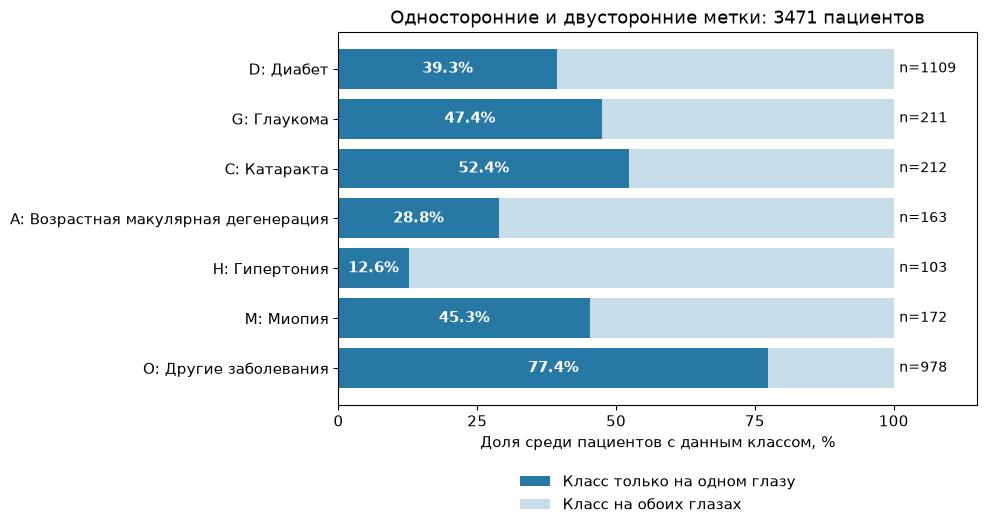

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.5))
positions = np.arange(len(DISEASES))
one = primary["unilateral_pct"].to_numpy()
ax.barh(positions, one, color="#2878a5", label="Класс только на одном глазу")
ax.barh(positions, 100 - one, left=one, color="#c6dce8", label="Класс на обоих глазах")
for y, label, share in zip(positions, DISEASES, one, strict=True):
    ax.text(
        share / 2,
        y,
        f"{share:.1f}%",
        ha="center",
        va="center",
        color="white",
        fontweight="bold",
    )
    ax.text(
        101, y, f"n={primary.at[label, 'affected_patients']}", va="center", fontsize=10
    )
ax.set_yticks(positions, [f"{label}: {CLASS_NAMES[label]}" for label in DISEASES])
ax.invert_yaxis()
ax.set_xlim(0, 115)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xlabel("Доля среди пациентов с данным классом, %")
ax.set_title(f"Односторонние и двусторонние метки: {int(eligible.sum())} пациентов")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncols=1, frameon=False)
fig.tight_layout()
plt.show()

## 5. Сколько пациентов имеют разные метки глаз

Разделяем разные вопросы: несовпадение **полных векторов классов** и наличие явной
нормы у одного глаза при патологии другого. Даже совпадение классов не означает
совпадения конкретных диагнозов или степени тяжести; особенно неоднороден класс O.

In [6]:
different = left.ne(right).any(axis=1)
one_normal = left["N"].ne(right["N"])
both_normal = left["N"].eq(1) & right["N"].eq(1)
both_abnormal = left["N"].eq(0) & right["N"].eq(0)
pair_categories = {
    "Оба глаза — норма по keywords": both_normal,
    "Один глаз — норма, другой — патология": one_normal,
    "Оба с патологией, классы совпадают": both_abnormal & ~different,
    "Оба с патологией, классы различаются": both_abnormal & different,
}
assert pd.DataFrame(pair_categories).sum(axis=1).eq(1).all()
pair_counts = pd.Series(
    {name: int((mask & eligible).sum()) for name, mask in pair_categories.items()}
)
display(
    pd.DataFrame(
        {"patients": pair_counts, "pct": (100 * pair_counts / eligible.sum()).round(2)}
    )
)

summary_records = []
for cohort, mask in [("all", all_patients), ("diagnostic_both_eyes", eligible)]:
    n = int(mask.sum())
    inherited_left = left.ne(df[LABELS])
    inherited_right = right.ne(df[LABELS])
    changed_eyes = int(
        inherited_left.loc[mask].any(axis=1).sum()
        + inherited_right.loc[mask].any(axis=1).sum()
    )
    extra_disease_assignments = int(
        ((df[DISEASES] == 1) & (left[DISEASES] == 0)).loc[mask].to_numpy().sum()
        + ((df[DISEASES] == 1) & (right[DISEASES] == 0)).loc[mask].to_numpy().sum()
    )
    # Один односторонний класс даёт одну лишнюю положительную метку при копировании на оба глаза.
    expected_extra = int(
        class_summary.loc[class_summary["cohort"].eq(cohort), "unilateral"].sum()
    )
    assert extra_disease_assignments == expected_extra
    summary_records.append(
        {
            "cohort": cohort,
            "patients": n,
            "eyes": 2 * n,
            "different_eye_vectors": int((different & mask).sum()),
            "different_eye_vectors_pct": 100 * int((different & mask).sum()) / n,
            "one_normal_one_abnormal": int((one_normal & mask).sum()),
            "one_normal_one_abnormal_pct": 100 * int((one_normal & mask).sum()) / n,
            "eyes_changed_by_patient_label_copy": changed_eyes,
            "eyes_changed_by_patient_label_copy_pct": 100 * changed_eyes / (2 * n),
            "extra_positive_disease_assignments": extra_disease_assignments,
        }
    )
cohort_summary = pd.DataFrame(summary_records)
display(cohort_summary.set_index("cohort").T.round(2))

,patients,pct
Оба глаза — норма по keywords,1136,32.73
"Один глаз — норма, другой — патология",820,23.62
"Оба с патологией, классы совпадают",1089,31.37
"Оба с патологией, классы различаются",426,12.27


cohort,all,diagnostic_both_eyes
patients,3500.00,3471.00
eyes,7000.00,6942.00
different_eye_vectors,1271.00,1246.00
different_eye_vectors_pct,36.31,35.90
one_normal_one_abnormal,845.00,820.00
one_normal_one_abnormal_pct,24.14,23.62
eyes_changed_by_patient_label_copy,1492.00,1467.00
eyes_changed_by_patient_label_copy_pct,21.31,21.13
extra_positive_disease_assignments,1569.00,1542.00


## 6. Примеры пар снимков

Детерминированно выбираем пациента с наименьшим ID в каждой из трёх категорий:
норма/патология, разные патологические классы, одинаковые патологические классы.
Это иллюстрации структуры разметки, **не независимая врачебная проверка** изображений.
Показываем отдельно keywords и классы каждого глаза, чтобы не смешивать их с метками пациента.

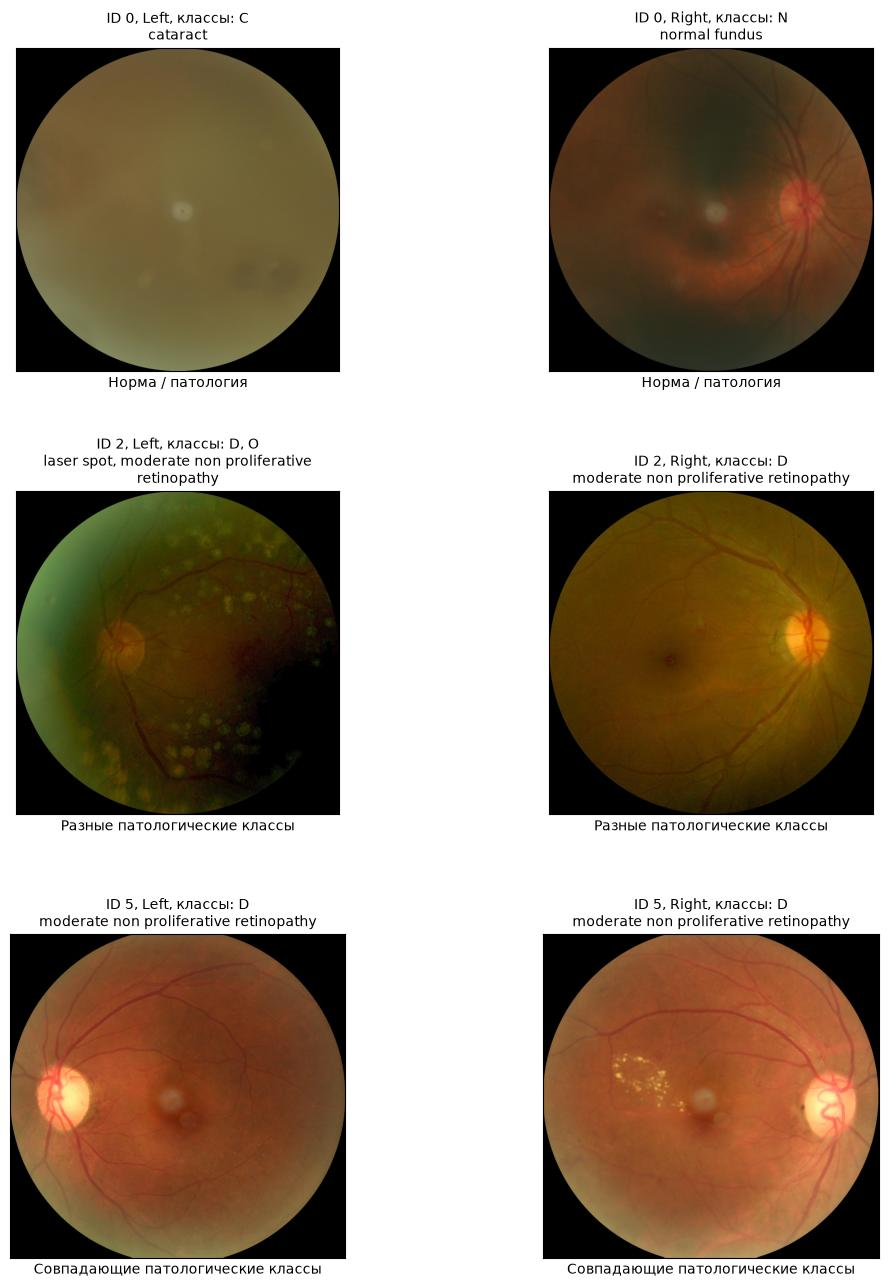

,category,patient_id
0,Норма / патология,0
1,Разные патологические классы,2
2,Совпадающие патологические классы,5


In [7]:
example_masks = {
    "Норма / патология": one_normal,
    "Разные патологические классы": both_abnormal & different,
    "Совпадающие патологические классы": both_abnormal & ~different,
}
fig, axes = plt.subplots(3, 2, figsize=(12, 13))
example_records = []
for row_idx, (category, mask) in enumerate(example_masks.items()):
    candidates = df.loc[mask & eligible].sort_values("ID")
    assert not candidates.empty, f"Нет примеров для категории {category}"
    idx = candidates.index[0]
    patient_id = int(df.at[idx, "ID"])
    example_records.append({"category": category, "patient_id": patient_id})
    for col_idx, (side, labels) in enumerate([("Left", left), ("Right", right)]):
        ax = axes[row_idx, col_idx]
        ax.imshow(
            crop_to_fundus(load_image(TRAIN_IMAGES_DIR / df.at[idx, f"{side}-Fundus"]))
        )
        eye_classes = ", ".join(label for label in LABELS if labels.at[idx, label])
        keywords = ", ".join(split_keywords(df.at[idx, f"{side}-Diagnostic Keywords"]))
        title = f"ID {patient_id}, {side}, классы: {eye_classes}\n" + textwrap.fill(
            keywords, 48
        )
        ax.set_title(title, fontsize=10)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel(category, fontsize=10)
fig.tight_layout(h_pad=3)
plt.show()
display(pd.DataFrame(example_records))

## 7. Выводы и ограничения

Числа ниже формируются из рассчитанных таблиц. Мы не сравниваем архитектуры и не
утверждаем, что асимметрия объясняет разницу качества single-eye и paired-моделей.

In [8]:
s = cohort_summary.set_index("cohort").loc["diagnostic_both_eyes"]
a = cohort_summary.set_index("cohort").loc["all"]
max_change = comparison["change_pp"].abs().max()
report = f"""# Одностороннее и двустороннее поражение глаз

## Данные и метод

ODIR-5K, data.xlsx: {len(df)} пациентов, {len(image_names)} снимков.
SHA-256 таблицы: `{source_sha256}`.
Метки глаз восстановлены существующей `eye_labels` из диагностических keywords.
Объединение совпало с исходными метками у всех {len(df)} пациентов.
Воспроизводимый расчёт, проверки и графики: `eda/eye_asymmetry.ipynb`.

## Ограничение разметки

У {len(ambiguous_eyes)} глаз ({int((~eligible).sum())} пациентов) описание содержит только
замечания о качестве без диагноза. Текущая функция относит их к N, что не доказывает
здоровье глаза. Основные результаты ниже — для {int(s["patients"])} пациентов,
у которых оба глаза имеют диагностические keywords. Исходные данные не менялись.
Полная выборка также рассчитана; максимальное изменение доли односторонних по классу
после исключения неоднозначных пар — {max_change:.2f} процентного пункта.

## Основные результаты

- Разные векторы классов у двух глаз: {int(s["different_eye_vectors"])}/{int(s["patients"])}
  ({s["different_eye_vectors_pct"]:.2f}%).
- Один глаз явно нормальный по keywords, второй с патологией:
  {int(s["one_normal_one_abnormal"])}/{int(s["patients"])} ({s["one_normal_one_abnormal_pct"]:.2f}%).
- При копировании меток пациента на оба снимка изменились бы цели для
  {int(s["eyes_changed_by_patient_label_copy"])}/{int(s["eyes"])} глаз
  ({s["eyes_changed_by_patient_label_copy_pct"]:.2f}%). Это доля затронутых глаз,
  а не доля ошибочных ячеек и не измеренная ошибка модели.
- Такое копирование добавило бы {int(s["extra_positive_disease_assignments"])} положительных
  назначений классов болезней, отсутствующих у соответствующего глаза по keywords.

| Класс | Пациентов с классом | Только слева | Только справа | Оба | Односторонних, % |
|---|---:|---:|---:|---:|---:|
"""
for label, row in primary.iterrows():
    report += (
        f"| {label} | {int(row['affected_patients'])} | {int(row['left_only'])} | "
        f"{int(row['right_only'])} | {int(row['bilateral'])} | {row['unilateral_pct']:.2f} |\n"
    )
report += f"""
Знаменатель последнего столбца — пациенты с данным классом.
Пациенты могут входить в несколько строк; строки не складываются.
Коды: D — диабет, G — глаукома, C — катаракта, A — возрастная макулярная дегенерация,
H — гипертония, M — миопия, O — другие заболевания.

## Проверка на полной выборке

Разные векторы классов: {int(a["different_eye_vectors"])}/{int(a["patients"])}
({a["different_eye_vectors_pct"]:.2f}%). Формальная пара N/патология:
{int(a["one_normal_one_abnormal"])}/{int(a["patients"])} ({a["one_normal_one_abnormal_pct"]:.2f}%).
Копирование меток изменяет цели {int(a["eyes_changed_by_patient_label_copy"])}/{int(a["eyes"])}
глаз ({a["eyes_changed_by_patient_label_copy_pct"]:.2f}%). Для интерпретации нормы
предпочтительна основная подвыборка выше.

## Решение для проекта

Для модели одного глаза использовать метки этого глаза, а метки пациента оставлять
для парной модели или оценки агрегированных предсказаний. Это количественное
обоснование подхода, уже применённого в PR с бейзлайном. Недиагностические описания
требуют отдельной политики обработки, а не автоматического признания нормой.

## Ограничения

- Это анализ текстовой разметки, не независимая клиническая верификация снимков.
- Совпадение объединённых меток не доказывает правильность меток каждого глаза.
- O объединяет разные заболевания; одинаковый O не означает один диагноз на обоих глазах.
- Совпадение классов не отражает степень тяжести и визуальное сходство глаз.
- Частоты описывают доступную выборку; перенос на другие популяции не проверялся.
- Из этих расчётов нельзя заключить, какая архитектура лучше: нужен отдельный эксперимент.

Машиночитаемые результаты: `reports/eye_asymmetry_classes.csv`,
`reports/eye_asymmetry_cohorts.csv`. Никакие модели не обучались,
данные и train/val/test не изменялись.
"""
display(Markdown(report))

# Одностороннее и двустороннее поражение глаз

## Данные и метод

ODIR-5K, data.xlsx: 3500 пациентов, 7000 снимков.
SHA-256 таблицы: `0507270f4edad478857a300514018eabefff5fe3ce04ed3b5bd4fcefbd5f54bf`.
Метки глаз восстановлены существующей `eye_labels` из диагностических keywords.
Объединение совпало с исходными метками у всех 3500 пациентов.
Воспроизводимый расчёт, проверки и графики: `eda/eye_asymmetry.ipynb`.

## Ограничение разметки

У 30 глаз (29 пациентов) описание содержит только
замечания о качестве без диагноза. Текущая функция относит их к N, что не доказывает
здоровье глаза. Основные результаты ниже — для 3471 пациентов,
у которых оба глаза имеют диагностические keywords. Исходные данные не менялись.
Полная выборка также рассчитана; максимальное изменение доли односторонних по классу
после исключения неоднозначных пар — 1.02 процентного пункта.

## Основные результаты

- Разные векторы классов у двух глаз: 1246/3471
  (35.90%).
- Один глаз явно нормальный по keywords, второй с патологией:
  820/3471 (23.62%).
- При копировании меток пациента на оба снимка изменились бы цели для
  1467/6942 глаз
  (21.13%). Это доля затронутых глаз,
  а не доля ошибочных ячеек и не измеренная ошибка модели.
- Такое копирование добавило бы 1542 положительных
  назначений классов болезней, отсутствующих у соответствующего глаза по keywords.

| Класс | Пациентов с классом | Только слева | Только справа | Оба | Односторонних, % |
|---|---:|---:|---:|---:|---:|
| D | 1109 | 205 | 231 | 673 | 39.31 |
| G | 211 | 65 | 35 | 111 | 47.39 |
| C | 212 | 58 | 53 | 101 | 52.36 |
| A | 163 | 20 | 27 | 116 | 28.83 |
| H | 103 | 6 | 7 | 90 | 12.62 |
| M | 172 | 31 | 47 | 94 | 45.35 |
| O | 978 | 355 | 402 | 221 | 77.40 |

Знаменатель последнего столбца — пациенты с данным классом.
Пациенты могут входить в несколько строк; строки не складываются.
Коды: D — диабет, G — глаукома, C — катаракта, A — возрастная макулярная дегенерация,
H — гипертония, M — миопия, O — другие заболевания.

## Проверка на полной выборке

Разные векторы классов: 1271/3500
(36.31%). Формальная пара N/патология:
845/3500 (24.14%).
Копирование меток изменяет цели 1492/7000
глаз (21.31%). Для интерпретации нормы
предпочтительна основная подвыборка выше.

## Решение для проекта

Для модели одного глаза использовать метки этого глаза, а метки пациента оставлять
для парной модели или оценки агрегированных предсказаний. Это количественное
обоснование подхода, уже применённого в PR с бейзлайном. Недиагностические описания
требуют отдельной политики обработки, а не автоматического признания нормой.

## Ограничения

- Это анализ текстовой разметки, не независимая клиническая верификация снимков.
- Совпадение объединённых меток не доказывает правильность меток каждого глаза.
- O объединяет разные заболевания; одинаковый O не означает один диагноз на обоих глазах.
- Совпадение классов не отражает степень тяжести и визуальное сходство глаз.
- Частоты описывают доступную выборку; перенос на другие популяции не проверялся.
- Из этих расчётов нельзя заключить, какая архитектура лучше: нужен отдельный эксперимент.

Машиночитаемые результаты: `reports/eye_asymmetry_classes.csv`,
`reports/eye_asymmetry_cohorts.csv`. Никакие модели не обучались,
данные и train/val/test не изменялись.


## 8. Экспорт результатов

Повторный запуск перезаписывает только три перечисленных артефакта исследования.
CSV содержит точные счётчики и доли без округления; отчёт округляет доли до двух знаков.

In [9]:
report_dir = PROJECT_ROOT / "reports"
report_dir.mkdir(exist_ok=True)
class_summary.to_csv(report_dir / "eye_asymmetry_classes.csv", index=False)
cohort_summary.to_csv(report_dir / "eye_asymmetry_cohorts.csv", index=False)
(report_dir / "eye_asymmetry.md").write_text(report, encoding="utf-8")
print(
    "Сохранены: reports/eye_asymmetry_classes.csv, reports/eye_asymmetry_cohorts.csv, reports/eye_asymmetry.md"
)

Сохранены: reports/eye_asymmetry_classes.csv, reports/eye_asymmetry_cohorts.csv, reports/eye_asymmetry.md
